<a href="https://colab.research.google.com/github/Roshan-Bhadane/ML_LABS/blob/main/ML_PR_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*   Student Name: Roshan Chandrakant Bhadane
*   Div: CSE-A
*   Practical Batch: A-1
*   Roll No: 01
*   Date: 28/10/2026
*   Practical No: 8
*   Practical Name: Visualize layers, activations, and loss using Keras. Build a 2-3 layer DNN for digit classification.

## 1. Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Flatten, Dense
from sklearn.metrics import confusion_matrix, classification_report

tf.random.set_seed(42)
np.random.seed(42)

## 2. Load MNIST Dataset

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


## 3. Display Sample Digit Images

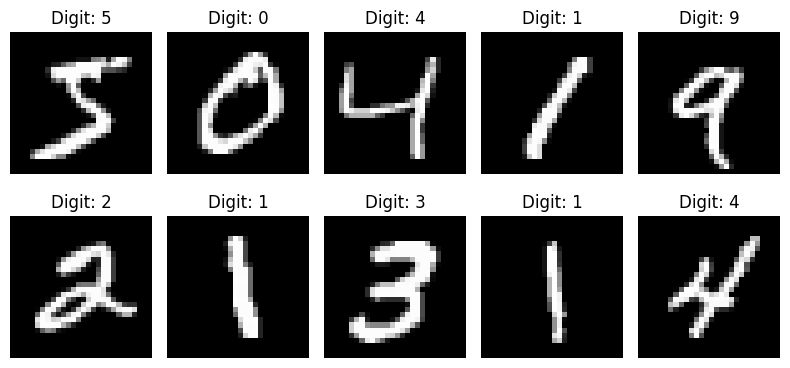

In [3]:
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Normalize Pixel Values

In [4]:
# scale pixel values from 0-255 to 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

## 5. Activation Functions Used in the Network

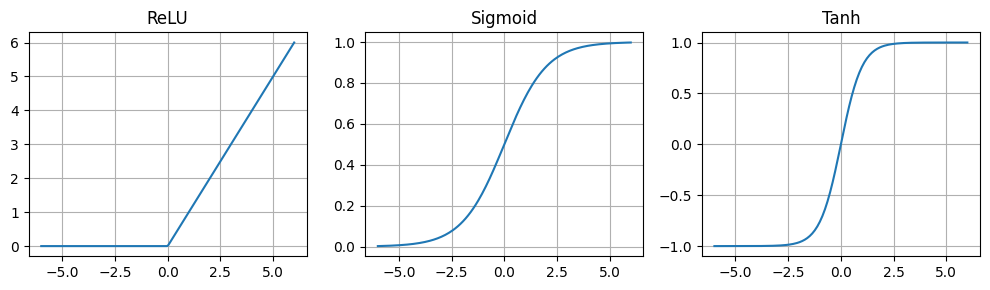

In [5]:
z = np.linspace(-6, 6, 200)

relu = np.maximum(0, z)
sigmoid = 1 / (1 + np.exp(-z))
tanh = np.tanh(z)

plt.figure(figsize=(10, 3))

for i, (name, values) in enumerate([("ReLU", relu), ("Sigmoid", sigmoid), ("Tanh", tanh)]):
    plt.subplot(1, 3, i + 1)
    plt.plot(z, values)
    plt.title(name)
    plt.grid(True)

plt.tight_layout()
plt.show()

## 6. Build a 3-Layer Neural Network

Two hidden layers use ReLU. The output layer uses Softmax to give a probability for each digit 0 to 9.

In [6]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

## 7. Visualize Layers

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

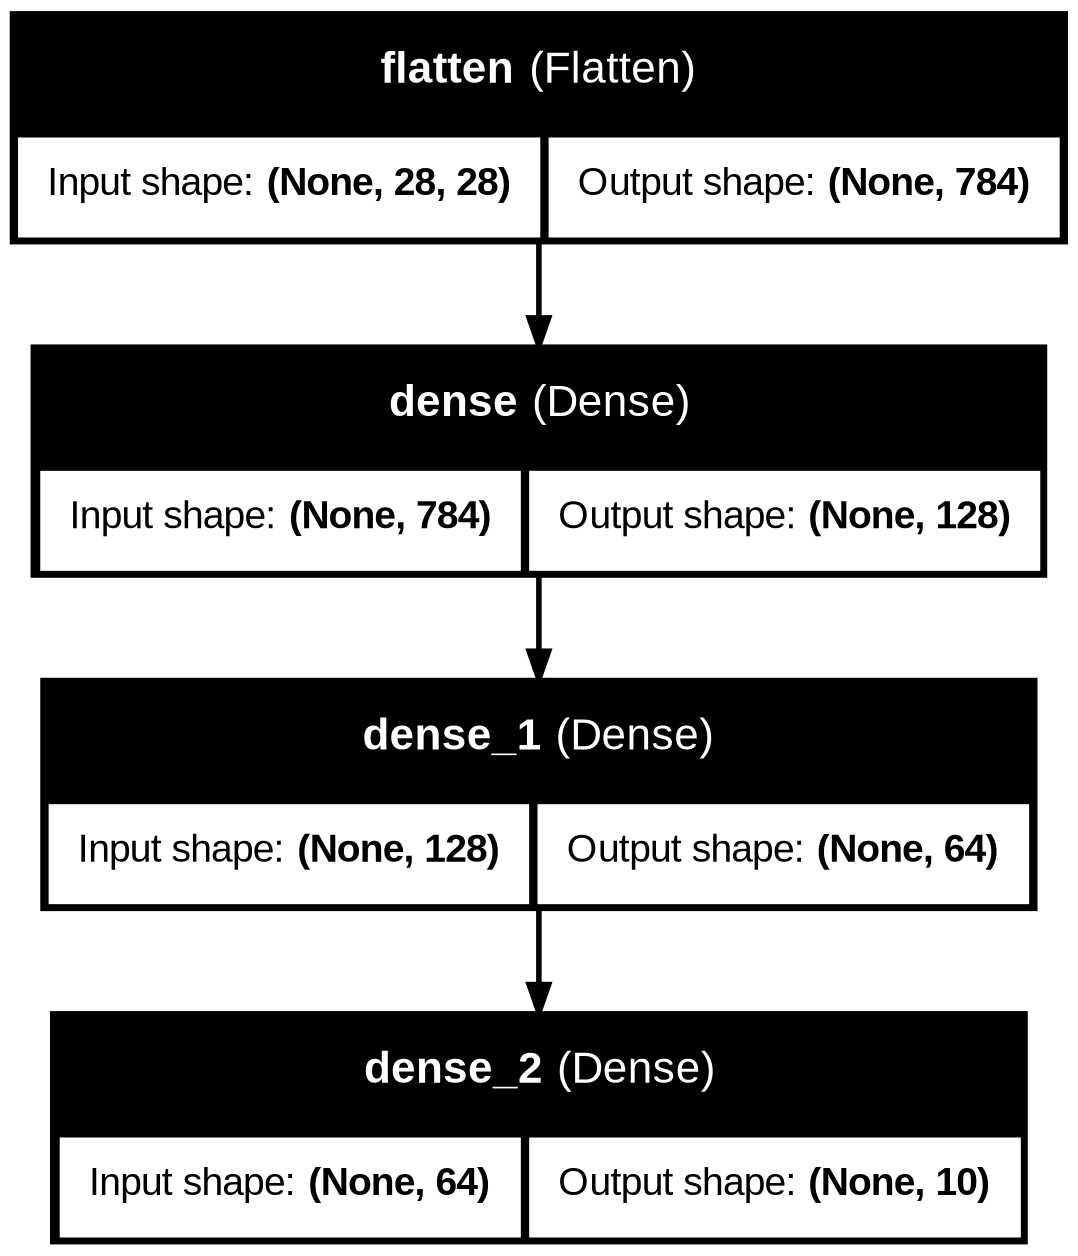

In [8]:
tf.keras.utils.plot_model(
    model,
    show_shapes=True,
    show_layer_names=True,
    to_file="dnn_architecture.png"
)

## 8. Compile the Model

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 9. Train the Model

In [10]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9256 - loss: 0.2517 - val_accuracy: 0.9652 - val_loss: 0.1174
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9684 - loss: 0.1052 - val_accuracy: 0.9703 - val_loss: 0.1018
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9782 - loss: 0.0710 - val_accuracy: 0.9747 - val_loss: 0.0936
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9839 - loss: 0.0518 - val_accuracy: 0.9762 - val_loss: 0.0906
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9873 - loss: 0.0399 - val_accuracy: 0.9737 - val_loss: 0.0933


## 10. Evaluate the Model

In [11]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9694 - loss: 0.1064
Test Loss: 0.1064310073852539
Test Accuracy: 0.9693999886512756


## 11. Visualize Loss and Accuracy

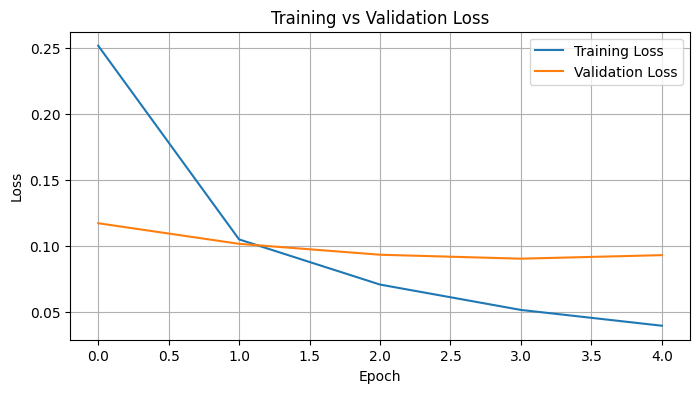

In [12]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

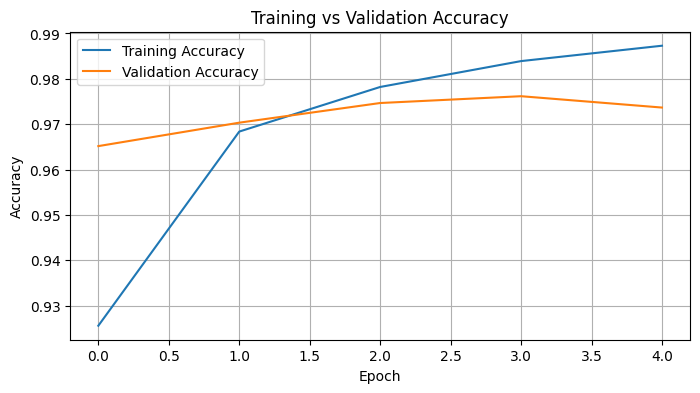

In [13]:
plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 12. Visualize Layer Activations

A second model is built that returns the output of every layer, so the activations for one digit can be seen as it passes through the network.

In [14]:
activation_model = Model(inputs=model.inputs,
                         outputs=[layer.output for layer in model.layers])

sample = x_test[:1]
activations = activation_model.predict(sample)

for layer, act in zip(model.layers, activations):
    print(layer.name, "->", act.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
flatten -> (1, 784)
dense -> (1, 128)
dense_1 -> (1, 64)
dense_2 -> (1, 10)


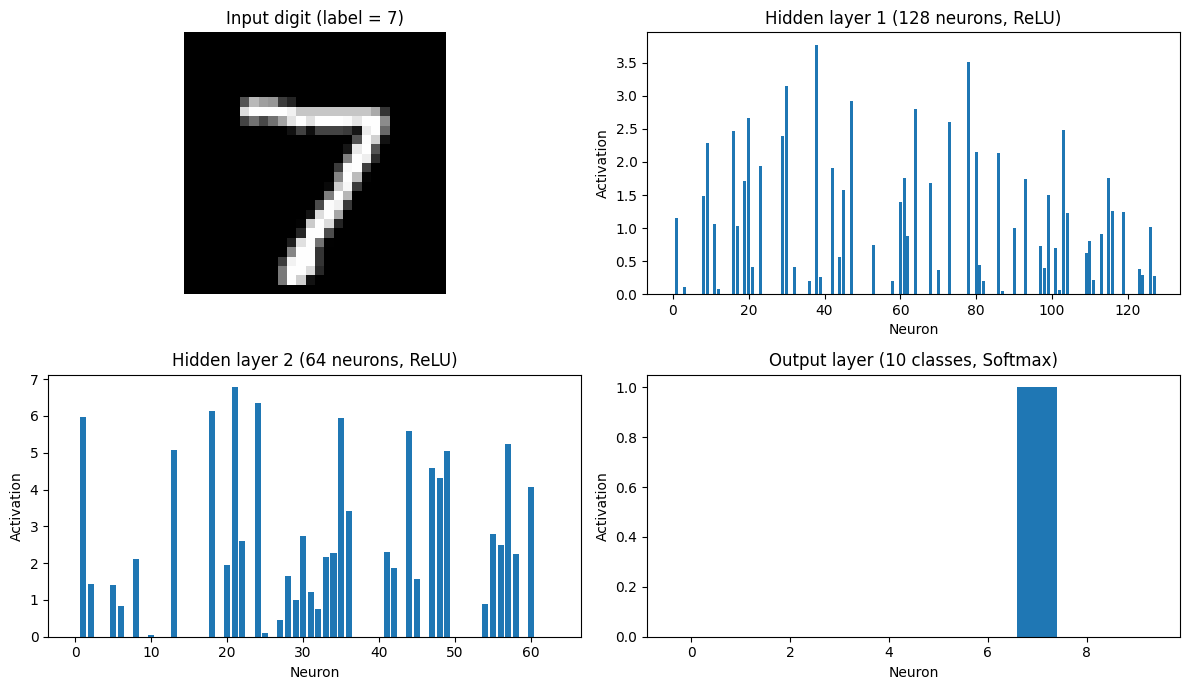

In [15]:
titles = ["Hidden layer 1 (128 neurons, ReLU)",
          "Hidden layer 2 (64 neurons, ReLU)",
          "Output layer (10 classes, Softmax)"]

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.imshow(x_test[0], cmap="gray")
plt.title(f"Input digit (label = {y_test[0]})")
plt.axis("off")

for i, (act, title) in enumerate(zip(activations[1:], titles)):
    plt.subplot(2, 2, i + 2)
    plt.bar(range(act.shape[1]), act[0])
    plt.title(title)
    plt.xlabel("Neuron")
    plt.ylabel("Activation")

plt.tight_layout()
plt.show()

## 13. Visualize Learned Weights of the First Layer

Weight matrix shape: (784, 128)


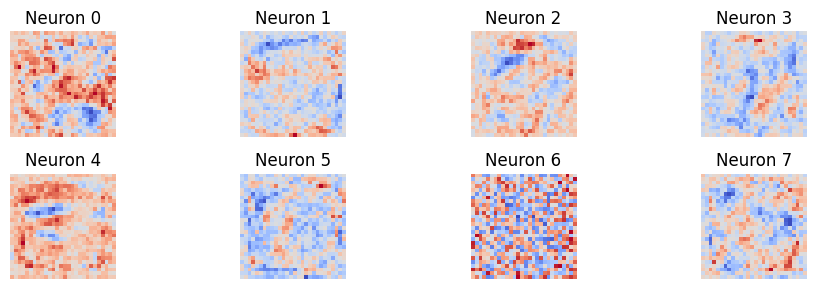

In [16]:
weights, biases = model.layers[1].get_weights()
print("Weight matrix shape:", weights.shape)

plt.figure(figsize=(10, 3))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(weights[:, i].reshape(28, 28), cmap="coolwarm")
    plt.title(f"Neuron {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 14. Predictions

In [17]:
predictions = model.predict(x_test)
y_pred = np.argmax(predictions, axis=1)

print("Predicted:", y_pred[:20])
print("Actual   :", y_test[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Actual   : [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


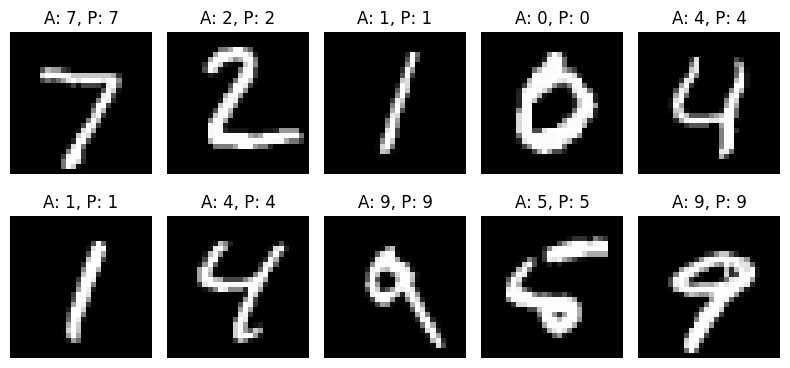

In [18]:
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"A: {y_test[i]}, P: {y_pred[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

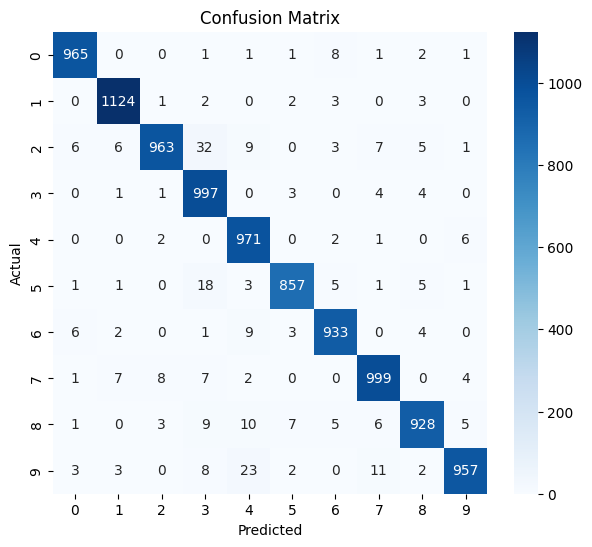

In [19]:
plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [20]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       980
           1       0.98      0.99      0.99      1135
           2       0.98      0.93      0.96      1032
           3       0.93      0.99      0.96      1010
           4       0.94      0.99      0.97       982
           5       0.98      0.96      0.97       892
           6       0.97      0.97      0.97       958
           7       0.97      0.97      0.97      1028
           8       0.97      0.95      0.96       974
           9       0.98      0.95      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



## 15. Conclusion

*   A 3-layer DNN (128 and 64 ReLU units, 10 Softmax outputs) was built in Keras to classify MNIST digits.
*   The layer summary and architecture diagram show the shape of data and number of parameters in each layer.
*   The activation plots show how each layer responds to a digit, and the Softmax output gives the probability of each class.
*   The training and validation loss curves show how well the model learns and whether it starts to overfit.